# Modelado experimental



## Criterios de evaluación y selección de modelos

Tal como se definió en los criterios de evaluación, y con el objetivo de conectar el rendimiento predictivo con los requerimientos y las necesidades del negocio, se utilizará la métrica MAPE (error porcentual absoluto medio) como criterio principal para evaluar el modelo destinado a realizar las predicciones. Asimismo, se considerará el trade-off sesgo-varianza para verificar que el modelo seleccionado presente un comportamiento estable y una adecuada capacidad de generalización.

En este contexto, y considerando el alcance de los entregables, no se priorizarán la interpretabilidad ni la posible latencia en producción.



## Librerías

In [212]:
import os
import sys
import warnings

warnings.filterwarnings(
    "ignore",
    category=Warning,
    module="pandas",
)

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [213]:
import pprint

In [214]:
import joblib

In [215]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd

In [216]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import graphviz
from IPython.display import Image

In [217]:
# ============================================================
# 3. Pruebas estadisticas
# ============================================================

import scipy.stats as stats
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [218]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================
from sklearn.linear_model import ElasticNet

from sklearn.ensemble import (
    RandomForestRegressor,
)

from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

from sklearn.tree import (
    DecisionTreeRegressor,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

In [219]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from src.cronological_split import chronological_panel_train_test_split, ChronologicalPanelSplitCV

from src.experiment_factory import ExperimentFactory
from src.model_optimizer import ModelOptimizer
from src.experiment_evaluator import ExperimentEvaluator
from src.experiment_tracker import ExperimentTracker
from sklearn.metrics import mean_absolute_percentage_error, make_scorer

In [220]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor



## Funciones complementarias



In [221]:
# Define funciones nombradas (globales)
def get_week_of_year(x):
    return x.dt.isocalendar().week.astype(int)

def get_quarter(x):
    return x.dt.quarter

def get_is_weekend(x):
    return (x.dt.dayofweek >= 5).astype('category')

def get_month(x):
    return x.dt.month.astype('category')

In [222]:
def convert_to_array(X):
    return np.asarray(X)

## Importación de datos



In [223]:
df_ml_path = '../data/1_bronze/df.csv'
df_ml = pd.read_csv(df_ml_path)
df_ml.sample(5)

,Unnamed: 0,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
261370,261370,289,2,2015-07-21,4692,463,1,0,0,0,d,a,6540.0,12.0,2007.0,0,NaN,NaN,NaN
494151,494151,542,3,2013-02-06,6282,541,1,1,0,0,a,a,7280.0,9.0,2012.0,1,1.0,2013.0,"Jan,Apr,Jul,Oct"
264793,264793,292,7,2013-12-01,0,0,0,0,0,0,a,a,1100.0,6.0,2009.0,0,NaN,NaN,NaN
87625,87625,96,1,2013-08-19,3870,520,1,0,0,1,a,a,8780.0,2.0,2005.0,1,37.0,2009.0,"Jan,Apr,Jul,Oct"
663663,663663,729,2,2013-08-27,10595,1099,1,1,0,1,c,c,8980.0,6.0,2011.0,0,NaN,NaN,NaN


> Los días donde las tiendas estan cerradas, las ventas son 0, por ende, se filtrara el DataFrame por esta variable.

In [224]:
store_open = df_ml['Open'] == 1
df_ml = df_ml[store_open]
df_ml.sample(n=5)

,Unnamed: 0,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
672729,672729,739,2,2013-08-13,10926,858,1,1,0,1,d,c,2770.0,6.0,2008.0,1,22.0,2011.0,"Jan,Apr,Jul,Oct"
820714,820714,901,6,2015-03-07,5091,470,1,0,0,0,a,c,3170.0,4.0,2014.0,0,NaN,NaN,NaN
359526,359526,394,5,2013-08-02,9286,687,1,1,0,1,d,a,10850.0,NaN,NaN,0,NaN,NaN,NaN
814725,814725,894,5,2014-01-10,10357,1260,1,1,0,0,a,a,190.0,11.0,2012.0,0,NaN,NaN,NaN
646290,646290,710,3,2014-03-26,3311,299,1,0,0,0,d,a,1500.0,9.0,2008.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"


### Separación de datos


In [225]:
#top_columns = joblib.load('../artifacts/top_columns.joblib')
#top_columns


#### `X` e `y` y conjuntos de entrenamiento y prueba (`train`-`test`)


In [226]:
X_train, X_test, y_train, y_test = chronological_panel_train_test_split(
    df_ml, 
    target_col= 'Sales',
    test_days=None, 
    test_size=0.07, # aprox 60 días
    filter_open_train=False
)

[ChronologicalPanelSplit] Fecha de corte: 2015-05-27
Train: 2013-01-01 -> 2015-05-27 | Shape X: (782404, 18)
Test:  2015-05-28 -> 2015-07-31 | Shape X: (61988, 18)


Samples:

In [227]:
#SAMPLE_SIZE = min(50000, len(X_train))
#X_train = X_train.sample(n=SAMPLE_SIZE, random_state=42)
#y_train = y_train.loc[X_train.index]



## Instanciación y creación de la grilla de hiperparámetros mediante `GridSearchCV`


Se probara un modelo robusto y capaces de capturar relaciones lineales y no lineales, así como robustez ante la varianza y sesgo.

### Métodos de reducción

In [228]:
reductions = {
    "options": {
        "Sin reducción": "passthrough",
    },

    "grids": {
        "Sin reducción": {},
    }
}

### Modelos avanzados: ensamblados y redes neuronales

* XGBoost
* MLP

#### XGBoost


In [229]:
xgboost = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    eval_metric="rmse",
    n_jobs=1,
    verbosity=0
)

grid_xgboost = {
    "n_estimators": [500, 800],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.05],
    "min_child_weight": [5, 10],
    "gamma": [0.1, 0.5],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
    "reg_lambda": [5, 10],
    "reg_alpha": [0.1, 1]
}

#### MLP


In [230]:
mlp = MLPRegressor(
    max_iter=500,
    early_stopping=True,
    random_state=42
)
grid_mlp = {
    "hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01]
}

### Combinaciones de modelos y grillas de hiperparámetros


In [231]:
models = {
    "options": {
        "XGBR": xgboost,
        #"MLP": mlp
    },

    "grids": {
        "XGBR": grid_xgboost,
        #"MLP": grid_mlp
    },
}

#### Carga de artefactos


In [232]:
preprocessor = joblib.load('../artifacts/pipeline_preprocessing_fe.joblib')

#### Pipeline


Columnas con mayor importancia de características (`feature importance`) en iteraciones previas:


In [233]:
columns = [
    'promo',
    'assortment',
    'promo2',
    'promo2sinceyear',
    'storetype_b',
    'storetype_a',
    'storetype_d',
    'storetype_c',
    'store',
    'dayofweek',
    'month',
    'competitiondistance',
    'competitionopensincemonth'
]

Construcción del pipeline final:

In [234]:
pipeline_ml = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selection", ColumnTransformer(
        transformers=[
            ("select", "passthrough", columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )),
    ("reduction", "passthrough"),
    ("model", clone(xgboost))
])

### Combinaciones de experimentos: estrategias de reducción de dimensionalidad × estrategias de modelado × hiperparámetros

In [235]:
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()

for experiment in experiments:
    print(f"Modelo: {experiment['nombre_modelo']}")
    print(f"Reducción: {experiment['reduccion']}")
    print(f"Grid: {experiment['param_grid']}")
    print("-" * 60)

Modelo: XGBR
Reducción: Sin reducción
Grid: {'model__n_estimators': [500, 800], 'model__max_depth': [3, 5], 'model__learning_rate': [0.03, 0.05], 'model__min_child_weight': [5, 10], 'model__gamma': [0.1, 0.5], 'model__subsample': [0.8], 'model__colsample_bytree': [0.8], 'model__reg_lambda': [5, 10], 'model__reg_alpha': [0.1, 1], 'reduction': ['passthrough'], 'model': [XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             

### Entrenamiento y optimización con `GridSearchCV`

In [236]:
cv = ChronologicalPanelSplitCV(
    n_splits=5,
    test_size=30,
    min_train_size=180,
    date_col='Date',
    gap=0,
    verbose=False
)

In [ ]:
scoring = {
    #"r2": "r2",
    "mae": "neg_mean_absolute_error",
    #"rmse": "neg_root_mean_squared_error",
}


optimizer = ModelOptimizer(
    pipeline=pipeline_ml,
    cv=5,
    scoring=scoring,
    refit="mae",
    search_type="random",
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)

# comentado para evitar reentrenamiento en futuras iteraciones

""" optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train
) """

### Evaluación general

In [ ]:
""" results = optimizer.get_results() """

In [ ]:
# lectura de resultados de iteraciones anteriores

results = pd.read_csv('../models/results.csv')

In [240]:
display(results.style.format("{:.2f}", subset=results.select_dtypes(include='number').columns))

,Modelo,Reducción,Método búsqueda,Score medio validación CV: mae,Score medio entrenamiento CV: mae,Desviación estándar validación CV: mae,Brecha score entrenamiento-validación CV: mae,Mejores parámetros
0,XGBR,Sin reducción,random,-887.05,-790.72,79.24,96.33,"{'reduction': 'passthrough', 'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__reg_alpha': 0.1, 'model__n_estimators': 800, 'model__min_child_weight': 10, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__gamma': 0.5, 'model__colsample_bytree': 0.8, 'model': XGBRegressor(base_score=None, booster=None, callbacks=None, colsample_bylevel=None, colsample_bynode=None, colsample_bytree=None, device=None, early_stopping_rounds=None, enable_categorical=True, eval_metric='rmse', feature_types=None, feature_weights=None, gamma=None, grow_policy=None, importance_type=None, interaction_constraints=None, learning_rate=None, max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None, max_delta_step=None, max_depth=None, max_leaves=None, min_child_weight=None, missing=nan, monotone_constraints=None, multi_strategy=None, n_estimators=None, n_jobs=1, num_parallel_tree=None, ...)}"


---

### Pipeline `XGBRegressor`

In [ ]:
# comentado para evitar reentrenamiento en futuras iteraciones

""" pipeline_xgb_sin_reduccion = optimizer.search_objects['XGBR', 'Sin reducción'].best_estimator_
pipeline_xgb_sin_reduccion """

pipeline_xgb_sin_reduccion = joblib.load('../models/pipeline_xgb_sin_reduccion.joblib')

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Unnamed: 0','Store','DayOfWeek',...,'Promo2SinceWeek','Promo2SinceYear', 'PromoInterval']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('gp_step', ...), ('general_preprocessing', ...), ...]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline canno

In [242]:
xgbr_sin_reduccion = pipeline_xgb_sin_reduccion.named_steps['model']

#### Evaluación individual

##### Durante el entrenamiento:


<Axes: >

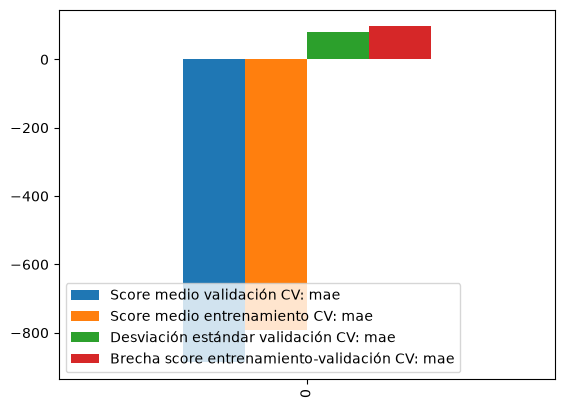

In [243]:
results[(results['Modelo']=='XGBR') & (results['Reducción']=='Sin reducción')].plot(kind='bar')

##### Con métrica externa:


In [244]:
# predicciones sobre test

y_pred_test = pipeline_xgb_sin_reduccion.predict(X_test)
y_pred_test

/var/folders/sf/zv8w99hn1570688_wf9y1h280000gn/T/ipykernel_75894/950236481.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return (x.dt.dayofweek >= 5).astype('category')


array([8100.8057, 7241.2637, 8737.419 , ..., 7684.384 , 7307.8057,
       4923.09  ], shape=(61988,), dtype=float32)

MAPE:

In [353]:
# MAPE sobre test

mape = mean_absolute_percentage_error(y_test, y_pred_test)* 100

print(np.round(mape, 3))



11.956


> Debido a la presencia de valores iguales a cero en la variable objetivo (correspondientes a los días en que las tiendas permanecen cerradas), el MAPE (Mean Absolute Percentage Error) no resulta una métrica adecuada para evaluar el modelo, ya que presenta indefiniciones o valores extremadamente elevados al calcular errores porcentuales sobre observaciones nulas o cercanas a cero. Esto puede distorsionar los resultados y reducir su representatividad respecto del desempeño real del modelo.
> 
> Por este motivo, se optará por utilizar métricas alternativas y complementarias:
>
> * NMAE (Normalized Mean Absolute Error): error absoluto medio normalizado por la media de los valores reales de la variable objetivo.
> * WAPE (Weighted Absolute Percentage Error): error absoluto total expresado como proporción del volumen total real, permitiendo evaluar el error porcentual agregado.
> * R² (Coeficiente de determinación): mide la proporción de la variabilidad de la variable objetivo explicada por el modelo.

R2:

In [246]:
r2 = r2_score(y_test, y_pred_test)

print('R2:',np.round(r2, 3))

R2: 0.855


MAE:

In [247]:
mae = mean_absolute_error(y_test, y_pred_test)

print('MAE:',np.round(mae, 3))

MAE: 830.367


WAPE:

In [357]:
wape = (
    np.sum(np.abs(y_test - y_pred_test))
    / np.sum(np.abs(y_test))
) * 100

print(f"WAPE: {wape :.3f}%")



WAPE: 11.623%


NMAE:

In [249]:
nmae = (
    mae
    / np.mean(np.abs(y_test))
)

print(f"NMAE: {nmae * 100:.3f}%")

NMAE: 11.623%


##### Interpretabilidad individual


In [250]:
nombres_variables = (

    pipeline_xgb_sin_reduccion
    .named_steps["selection"]
    .get_feature_names_out()

)

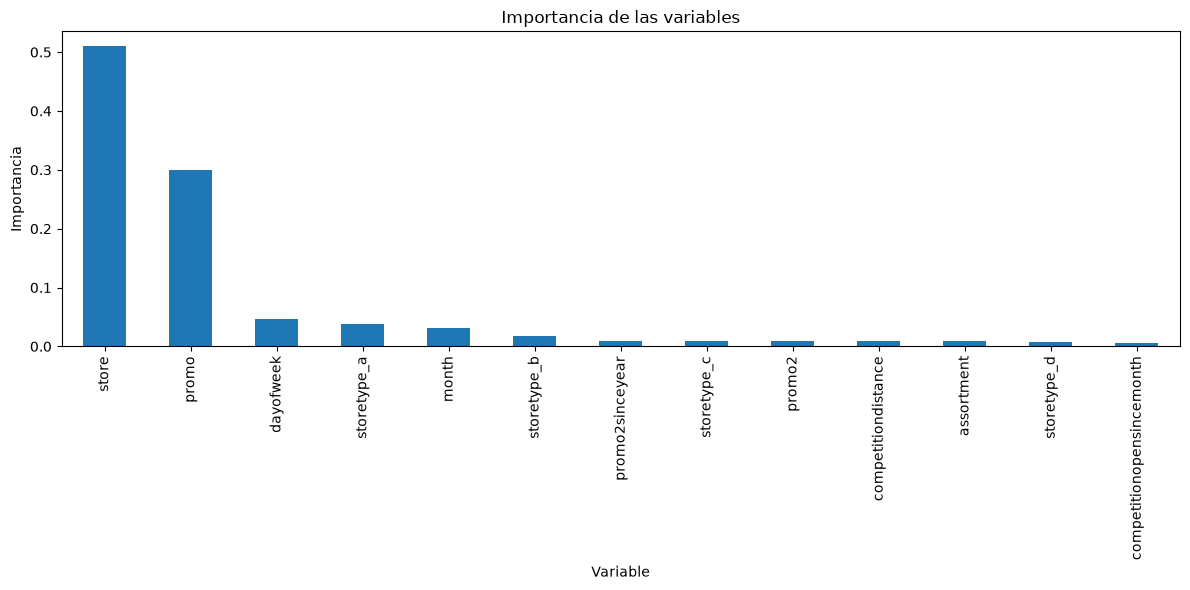

In [251]:
feature_importance = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": xgbr_sin_reduccion.feature_importances_,
}).sort_values(
    "Importancia",
    ascending=False,
)

feature_importance.plot(
    kind='bar',
    x='Variable',
    y='Importancia',
    figsize=(12, 6),
    legend=False
)

plt.xticks(rotation=90)
plt.ylabel('Importancia')
plt.title('Importancia de las variables')
plt.tight_layout()
plt.show()

### Entregable

##### Evaluación por tienda

In [252]:
def calculate_metrics(group):

    y_test = group['y_test']
    y_pred = group['y_pred']

    mae = mean_absolute_error(y_test, y_pred)

    wape = (
        np.sum(np.abs(y_test - y_pred))
        / np.sum(np.abs(y_test))
    ) if np.sum(np.abs(y_test)) != 0 else np.nan

    return pd.Series({
        'MAE': mae,
        'WAPE': wape * 100,
    })

In [253]:
df_eval = pd.DataFrame({
    'Store': df_ml.loc[X_test.index, 'Store'],
    'y_test': y_test,
    'y_pred': y_pred_test
})

metrics_store = (
    df_eval
    .groupby('Store')
    .apply(calculate_metrics)
    .reset_index()
).sort_values(by=['WAPE'])

metrics_store.head()

,Store,MAE,WAPE
816,817,1213.261597,5.717206
732,733,876.000000,5.809890
561,562,1042.000732,5.896686
725,726,657.752930,5.913487
762,763,382.212128,6.114642


##### Predicciones a entregar (últimos 60 días)

In [254]:
sales_60 = pd.Series(name='Sales', data=y_pred_test, index=y_test.index)
df_y_pred_60 = pd.DataFrame(data=sales_60, index=y_test.index)
df_y_pred_60 = pd.concat([X_test.loc[y_test.index][['Date', 'Store']], df_y_pred_60], axis=1)
df_y_pred_60

,Date,Store,Sales
32298,2015-05-28,36,8100.805664
684896,2015-05-28,753,7241.263672
838184,2015-05-28,921,8737.418945
164126,2015-05-28,182,4339.324707
7600,2015-05-28,9,5754.217285
...,...,...,...
718008,2015-07-31,789,3608.341309
248518,2015-07-31,274,3886.638428
247576,2015-07-31,273,7684.383789
630704,2015-07-31,693,7307.805664


##### Info general

Cantidad de tiendas analizadas:

In [255]:
tiendas_analizadas = X_train['Store'].nunique()
tiendas_analizadas

1115

Horizonte temporal de las predicciones:

In [256]:
horizonte_temporal = (X_test['Date'].max() - X_test['Date'].min()).days
horizonte_temporal

64

Ventas totales proyectadas:

In [257]:
ventas_totales_predichas = y_pred_test.sum().round(3)
ventas_totales_predichas

np.float32(4.245986e+08)

Promedio diario de ventas proyectadas:

In [258]:
promedio_diario_ventas_proyectadas = df_y_pred_60.groupby(by=['Date'])['Sales'].agg('mean')
promedio_diario_ventas_proyectadas

Date
2015-05-28    6042.994990
2015-05-29    6878.126606
2015-05-30    6104.817458
2015-05-31    7306.570030
2015-06-01    9813.683173
                 ...     
2015-07-27    9820.116147
2015-07-28    8276.935446
2015-07-29    7716.112973
2015-07-30    7627.601024
2015-07-31    7529.696204
Name: Sales, Length: 65, dtype: float64

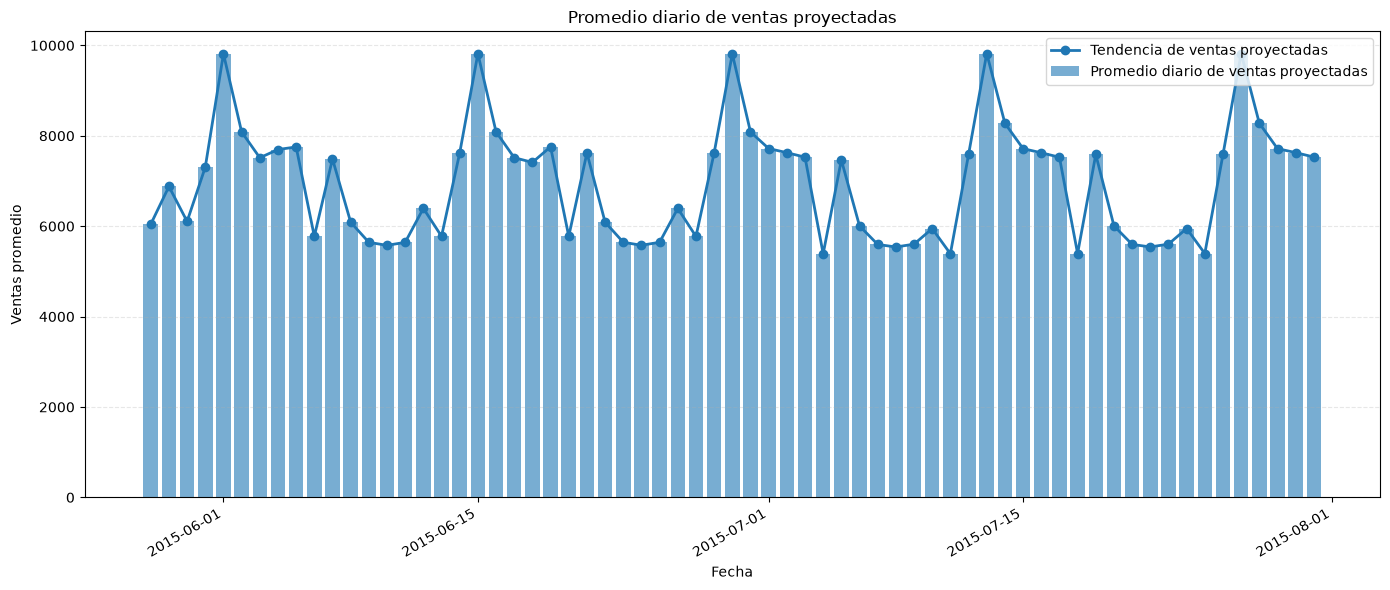

In [361]:
# Crear la figura

fig, ax = plt.subplots(figsize=(14, 6))

# Gráfico de barras

ax.bar(

    promedio_diario_ventas_proyectadas.index,

    promedio_diario_ventas_proyectadas.values,

    label='Promedio diario de ventas proyectadas',

    alpha=0.6

)

# Gráfico de líneas superpuesto

ax.plot(

    promedio_diario_ventas_proyectadas.index,

    promedio_diario_ventas_proyectadas.values,

    marker='o',

    linewidth=2,

    label='Tendencia de ventas proyectadas'

)

# Configurar el gráfico

ax.set_title('Promedio diario de ventas proyectadas')

ax.set_xlabel('Fecha')

ax.set_ylabel('Ventas promedio')

ax.legend()

ax.grid(axis='y', linestyle='--', alpha=0.3)

# Formatear las fechas del eje X

fig.autofmt_xdate()

plt.tight_layout()

plt.show()

Ventas promedio totales proyectadas:

In [363]:
promedio_general_ventas_diarias_proyectadas = promedio_diario_ventas_proyectadas.mean()
promedio_general_ventas_diarias_proyectadas

np.float64(6950.804262181095)

Grafico de linea. Ventas históricas vs. proyectadas.

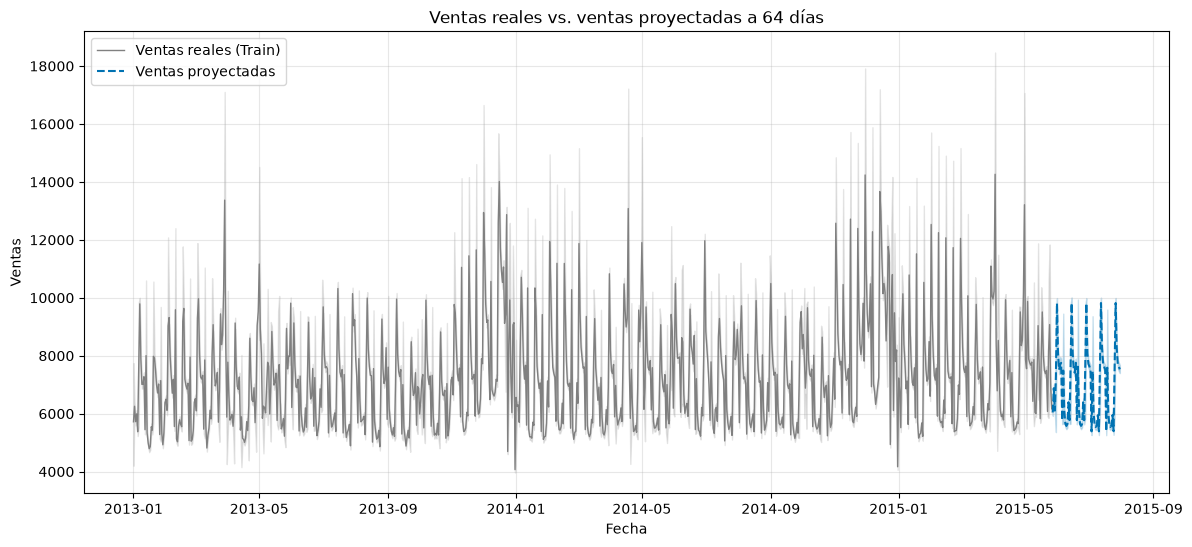

In [355]:
plt.figure(figsize=(14, 6))

# Ventas reales de entrenamiento
sns.lineplot(
    x=X_train['Date'],
    y=y_train,
    color='grey',
    linewidth=1,
    label='Ventas reales (Train)'
)

# Ventas proyectadas sobre el período de test
sns.lineplot(
    x=X_test['Date'],
    y=y_pred_test,
    color='#0072B2',
    linewidth=1.5,
    linestyle='--',
    label=f'Ventas proyectadas'
)

plt.title(f'Ventas reales vs. ventas proyectadas a {horizonte_temporal} días')
plt.xlabel('Fecha')
plt.ylabel('Ventas')
plt.legend()
plt.grid(alpha=0.3)

plt.show()


* Comportamiento del modelo: La proyección (línea azul punteada, entre mediados de 2015 y agosto de 2015) conserva el patrón cíclico semanal y se mueve en un rango similar al nivel base habitual (~6.000 a ~10.000), pero tiende a suavizar los picos extremos que se observan en el histórico (como los repuntes de fin de año en 2013 y 2014 o ciertos picos puntuales por encima de 14.000–18.000).

* Alineación con el negocio: Para el horizonte de planificación financiera del CFO (centrado en las próximas 6 semanas, y aquí extendido a 64 días), la proyección entrega una línea base estable útil para comparar el ritmo ordinario de ingresos entre tiendas, aunque conviene vigilar el MAPE en períodos de alta volatilidad o estacionalidad marcada para no subestimar picos de caja al decidir inversiones en renovación.

Grafíco de barra. Top 10 tiendas con mayores ventas proyectadas:

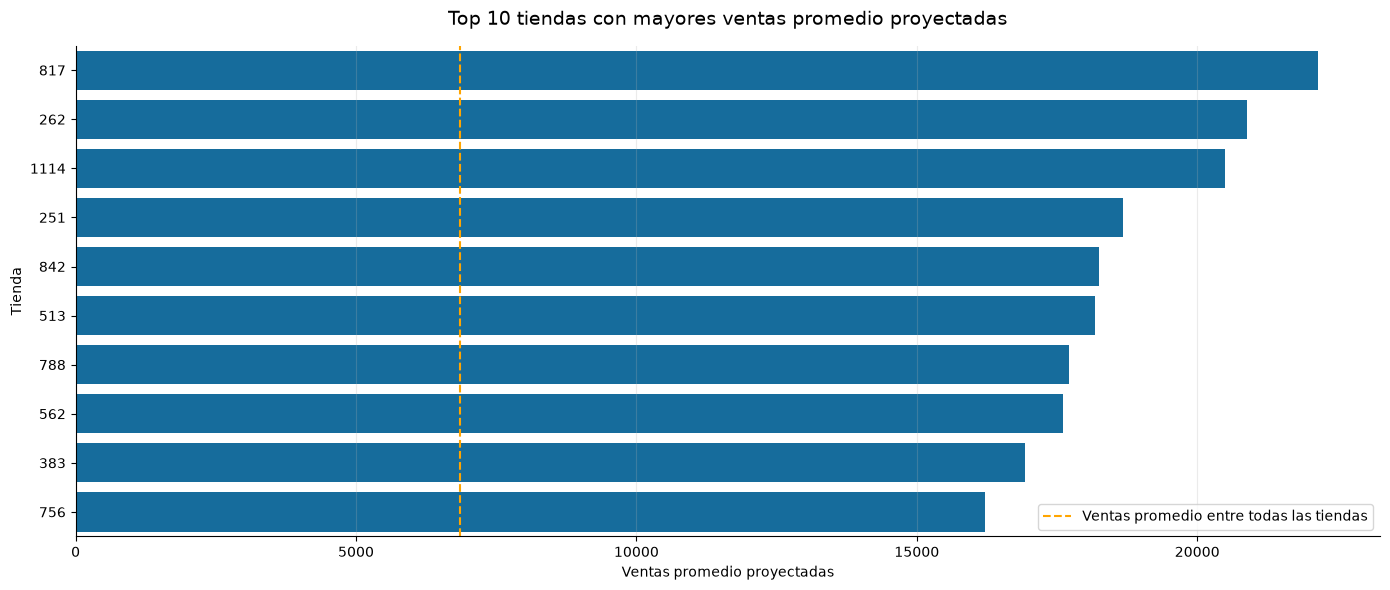

In [260]:
plt.figure(figsize=(14, 6))

# Calcular promedio y seleccionar Top 10
df_top10 = (
    df_y_pred_60.groupby('Store', as_index=False)['Sales']
    .mean()
    .sort_values(by='Sales', ascending=False)
    .head(10)
)

# ventas promedio proyectadas entre todas las tiendas

df_y_pred_60_mean = df_y_pred_60['Sales'].mean()

# Gráfico
sns.barplot(
    data=df_top10,
    x='Sales',
    y='Store',
    color='#0072B2',
    orient='h',
    order= df_top10['Store']
)

plt.axvline(df_y_pred_60_mean, label='Ventas promedio entre todas las tiendas', linestyle='--', color='orange')
plt.title('Top 10 tiendas con mayores ventas promedio proyectadas',
          fontsize=14, pad=15)

plt.xlabel('Ventas promedio proyectadas')
plt.ylabel('Tienda')

plt.legend()

plt.grid(axis='x', alpha=0.25)
sns.despine()

plt.tight_layout()
plt.show()

* Hallazgo principal: Las diez tiendas líderes —encabezadas por las sucursales 817, 262 y 1114, que superan los €20.000 de venta diaria promedio proyectada— duplican con holgura y hasta triplican la media general de la cadena (ubicada cerca de €6.800–€7.000, línea naranja punteada). 

* Alineación con el negocio: Esta diferenciación entrega al CFO un criterio cuantitativo directo para jerarquizar el presupuesto de renovación: estas sucursales concentran el mayor potencial de generación de ingresos futuros, por lo que permiten evaluar tanto inversiones orientadas a proteger y maximizar el retorno en tiendas de mayor facturación como la capacidad de repago de cada reforma. 

Grafico de barra apilada. Top 10 tiendas con mayor crecimiento proyectado:

In [290]:
df_y_train = pd.concat([
    X_train.loc[y_train.index, ['Date', 'Store']],
    y_train.rename('Sales')
], axis=1)

In [291]:
df_comparison = (
    df_y_pred_60.groupby('Store', as_index=False)['Sales'].mean()
    .merge(
        df_y_train.groupby('Store', as_index=False)['Sales'].mean(),
        on='Store',
        how='inner',
        suffixes=('_pred', '_train')
    )
)

In [ ]:
df_comparison['Crecimiento'] = df_comparison['Sales_train'] - df_comparison['Sales_pred']

In [292]:
top_10_crecimiento = df_comparison.sort_values(by='Crecimiento', ascending=False).head(10)
top_10_crecimiento

,Store,Sales_pred,Sales_train,Crecimiento
585,586,14521.342773,15104.037448,582.694675
1017,1018,11254.684570,11792.915978,538.231408
594,595,14566.041016,15024.674451,458.633435
250,251,18671.751953,19101.013812,429.261859
559,560,13125.256836,13530.907381,405.650545
561,562,17604.654297,17991.687571,387.033274
309,310,7818.323242,8196.828125,378.504883
468,469,11559.654297,11928.064560,368.410264
382,383,16932.892578,17299.806897,366.914318
334,335,12899.863281,13264.909920,365.046639


/var/folders/sf/zv8w99hn1570688_wf9y1h280000gn/T/ipykernel_75894/3389804468.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Variación')


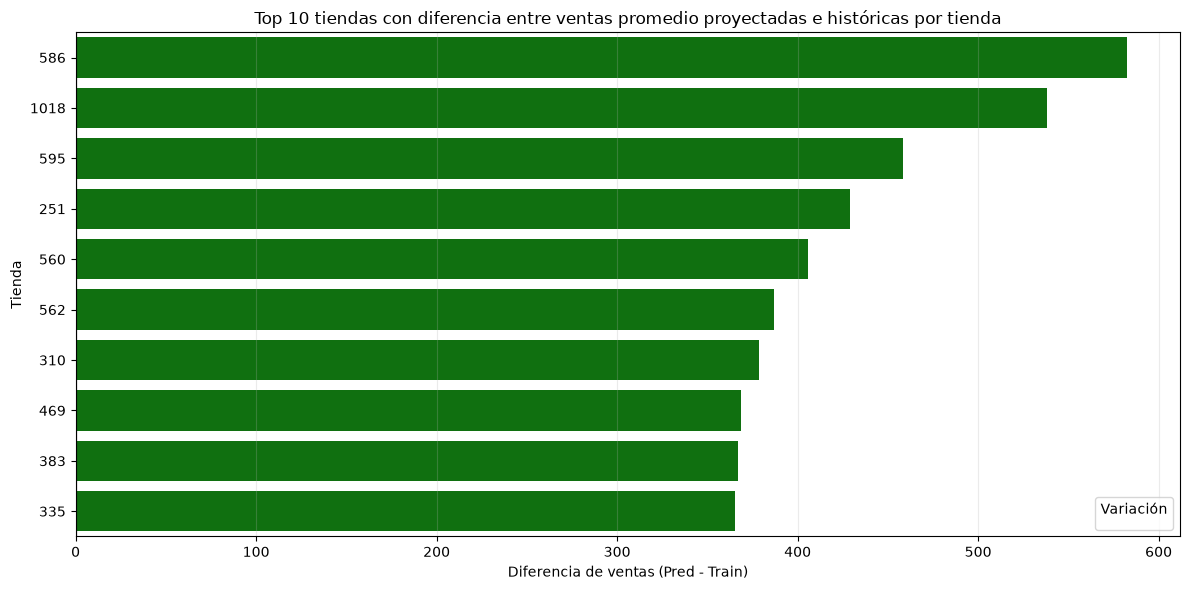

In [359]:
plt.figure(figsize=(12, 6))

sns.barplot(

    data=top_10_crecimiento,

    x='Crecimiento',

    y='Store',

    dodge=False,

    orient='horizontal',

    order=top_10_crecimiento.Store,

    color='green'

)

plt.axvline(0, color='black', linewidth=0.8)

plt.title('Top 10 tiendas con diferencia entre ventas promedio proyectadas e históricas por tienda')

plt.xlabel('Diferencia de ventas (Pred - Train)')

plt.ylabel('Tienda')

plt.grid(axis='x', alpha=0.25)

plt.legend(title='Variación')

plt.tight_layout()

plt.show()

* Hallazgo principal: Las diez tiendas con mayor incremento proyectado presentan una diferencia positiva de entre €365 y €580 al comparar su venta promedio proyectada para los próximos 60 días frente a su promedio histórico de entrenamiento (lideradas por las tiendas 586 con +€580, 1018 con +€538 y 595 con +€458). En términos de escala operativa, un desplazamiento de ~€500 en el promedio del período es una variación acotada y representa apenas entre el 11,8% y el 18,7% de la desviación estándar de €3.095, lo que demuestra que el modelo proyecta continuidad y estabilidad respecto al histórico, sin saltos bruscos ni sobreestimaciones artificiales. 

* Alineación con el negocio: Para el CFO, este comportamiento aporta doble valor: confirma que las estimaciones a futuro mantienen una base prudente —evitando inflar expectativas de ingresos al evaluar el retorno de una reforma— y permite identificar sucursales con una leve mejora en su nivel promedio de facturación (como 251, 562 y 383, que además figuran entre las de mayor venta promedio proyectada), aunque por tratarse de diferencias moderadas de promedio deben complementarse con criterios financieros y operativos antes de asignar el presupuesto de renovación. 

Grafico de barra doble. Top 10 tiendas con mayor decrecimiento proyectado:

In [299]:
top_10_decrecimiento = df_comparison.sort_values(by='Crecimiento', ascending=False).tail(10)
top_10_decrecimiento

,Store,Sales_pred,Sales_train,Crecimiento
461,462,5039.093750,4848.203039,-190.890711
261,262,20878.966797,20683.937286,-195.029511
1029,1030,3835.972900,3608.437845,-227.535055
816,817,22151.703125,21798.733516,-352.969609
298,299,6635.349609,6103.962056,-531.387553
800,801,5356.233398,4793.065934,-563.167464
109,110,5150.297852,4525.093407,-625.204445
731,732,6312.672363,5665.287286,-647.385077
121,122,7213.015625,6359.879268,-853.136357
452,453,8837.991211,7618.948905,-1219.042306


/var/folders/sf/zv8w99hn1570688_wf9y1h280000gn/T/ipykernel_75894/1187209653.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Variación')


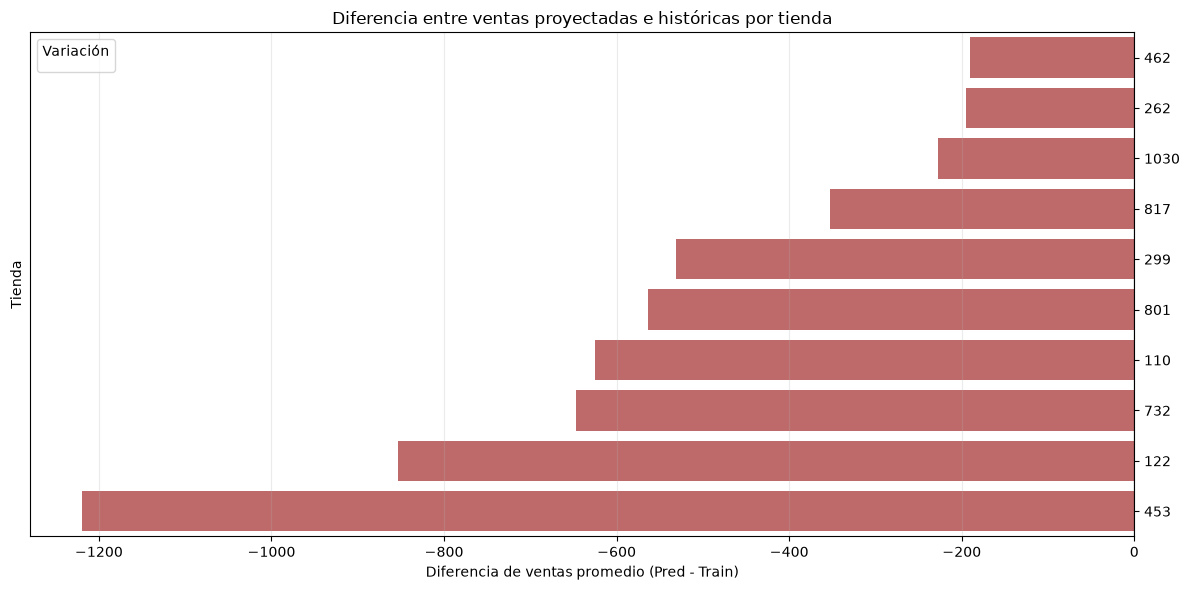

In [344]:
plt.figure(figsize=(12, 6))

sns.barplot(

    data=top_10_decrecimiento,

    x='Crecimiento',

    y='Store',

    dodge=False,

    color='indianred',

    orient='horizontal',

    order=top_10_decrecimiento.Store

)

plt.axvline(0, color='black', linewidth=0.8)

plt.title('Diferencia entre ventas proyectadas e históricas por tienda')

plt.xlabel('Diferencia de ventas promedio (Pred - Train)')

plt.ylabel('Tienda')

# Mover las etiquetas del eje Y a la derecha

plt.gca().yaxis.tick_right()

plt.grid(axis='x', alpha=0.25)

plt.legend(title='Variación')

plt.tight_layout()

plt.show()

* Hallazgo principal: Las diez tiendas con mayor contracción proyectada presentan una diferencia negativa de entre -€190 y -€1.215 al comparar su venta promedio proyectada para los próximos 60 días frente a su promedio histórico de entrenamiento, encabezadas por las sucursales 453 (-€1.215), 122 (-€850) y 732 (-€645). Frente a la desviación estándar de €3.095, estos retrocesos en el promedio del período equivalen a entre el 6% y el 39% de una desviación estándar (superando en magnitud absoluta a las mayores alzas proyectadas). Además, destacan las tiendas 817 (-€350) y 262 (-€195), que aunque lideran el ranking de facturación promedio proyectada, exhiben un ajuste acotado a la baja respecto a su media histórica. 


* Alineación con el negocio: Para el CFO, este resultado actúa como un radar de riesgo y eficiencia de capital: permite postergar o auditar antes de renovar aquellas sucursales con retrocesos más marcados en su nivel promedio esperado (como la 453 o la 122) para determinar si la caída obedece a estacionalidad del período, competencia o deterioro operativo, evitando comprometer presupuesto donde la facturación media tiende a contraerse. En casos como 817 y 262, la variación en su promedio es marginal frente a su alto nivel de facturación (>€20.000), por lo que mantienen su atractivo para inversión bajo un criterio financiero prudente.

Grafico combinado: Puntos + caja + Barra. Desempeño predictivo del modelo en promedio, y segmentado por tienda:

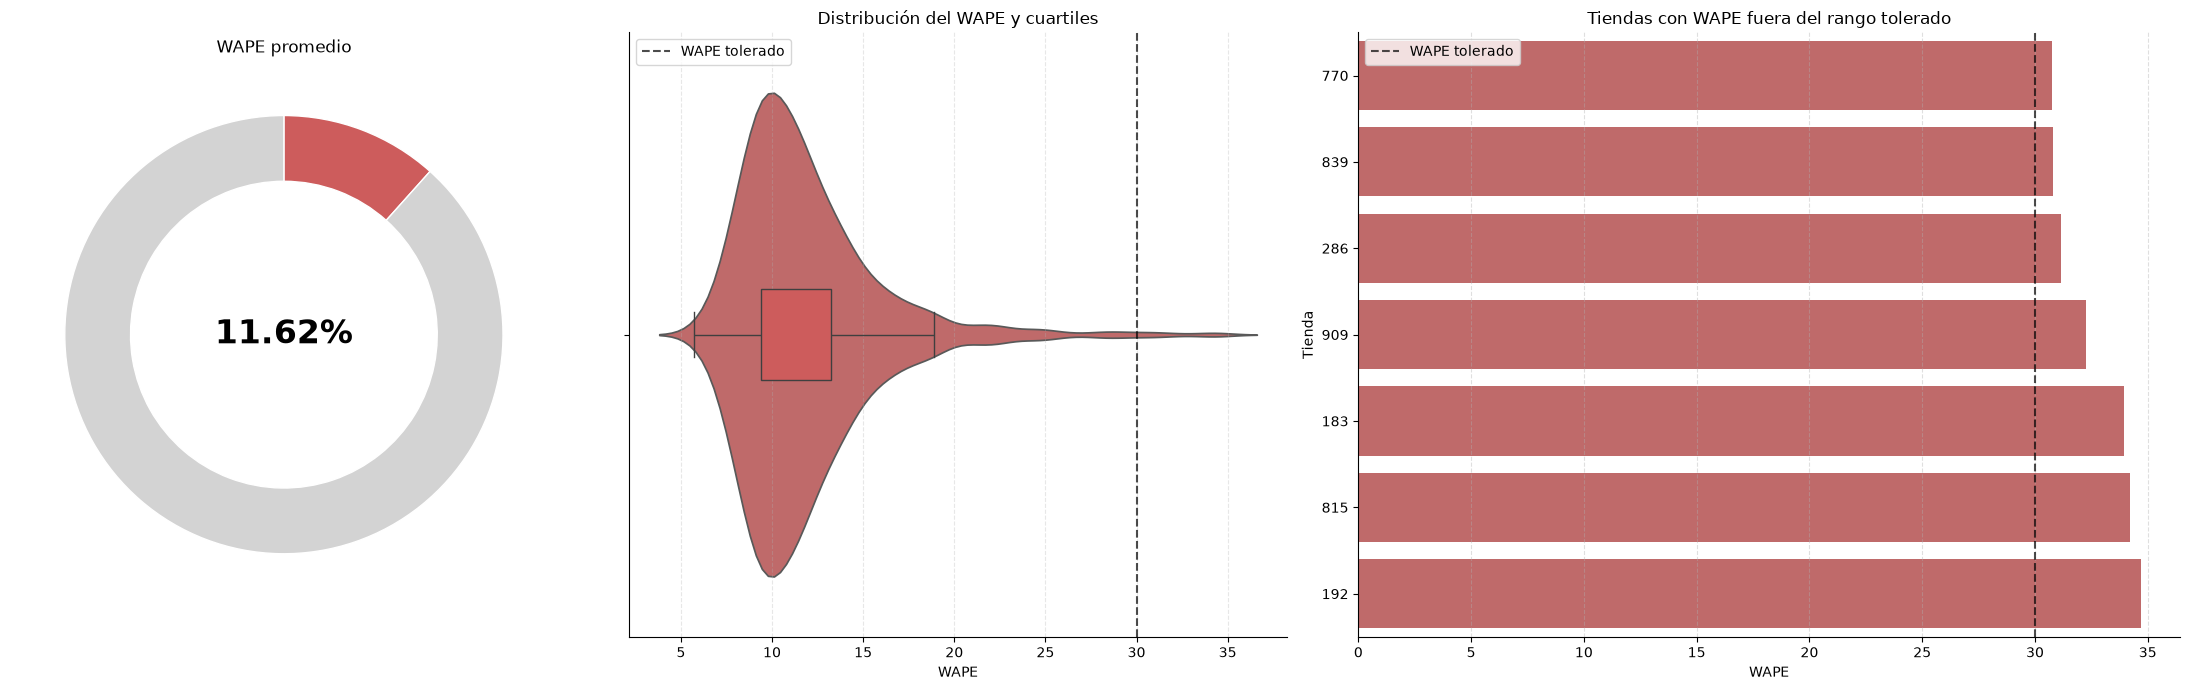

In [358]:
# Filtrar tiendas fuera del rango tolerado
tiendas_wape_no_tolerado = metrics_store['WAPE'] >= 30

df_tiendas_wape_no_tolerado = metrics_store.loc[
    tiendas_wape_no_tolerado
].copy()

df_tiendas_wape_no_tolerado['Store'] = (
    df_tiendas_wape_no_tolerado['Store'].astype(str)
)

# Parámetros
umbral = 100

# Crear figura con tres gráficos
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    figsize=(22, 7),
    gridspec_kw={'width_ratios': [1, 1.2, 1.5]}
)

# --------------------------------------------------
# GRÁFICO 1: ANILLO - WAPE PROMEDIO
# --------------------------------------------------

ax1.pie(
    [min(wape, umbral), max(0, umbral - wape)],
    startangle=90,
    counterclock=False,
    wedgeprops={
        'width': 0.3,
        'edgecolor': 'white'
    },
    colors=['indianred', 'lightgray']
)

ax1.text(
    0, 0,
    f'{wape:.2f}%',
    ha='center',
    va='center',
    fontsize=24,
    fontweight='bold'
)

ax1.set_title('WAPE promedio')


# --------------------------------------------------
# GRÁFICO 2: VIOLÍN + CAJA - DISTRIBUCIÓN DEL WAPE
# --------------------------------------------------

sns.violinplot(
    data=metrics_store,
    x='WAPE',
    inner=None,
    color='indianred',
    ax=ax2
)

sns.boxplot(
    data=metrics_store,
    x='WAPE',
    width=0.15,
    showfliers=False,
    boxprops={'facecolor': 'indianred', 'zorder': 3},
    medianprops={'color': 'white', 'linewidth': 2},
    ax=ax2
)

ax2.axvline(
    30,
    color='black',
    linestyle='--',
    alpha=0.7,
    label='WAPE tolerado'
)

ax2.set_title('Distribución del WAPE y cuartiles')
ax2.set_xlabel('WAPE')
ax2.set_ylabel('')
ax2.grid(axis='x', linestyle='--', alpha=0.3)
ax2.legend()


# --------------------------------------------------
# GRÁFICO 3: BARRAS - TIENDAS FUERA DEL UMBRAL
# --------------------------------------------------

sns.barplot(
    data=df_tiendas_wape_no_tolerado.sort_values('WAPE'),
    x='WAPE',
    y='Store',
    color='indianred',
    ax=ax3
)

ax3.axvline(
    30,
    color='black',
    linestyle='--',
    alpha=0.7,
    label='WAPE tolerado'
)

ax3.set_title('Tiendas con WAPE fuera del rango tolerado')
ax3.set_xlabel('WAPE')
ax3.set_ylabel('Tienda')
ax3.grid(axis='x', linestyle='--', alpha=0.4)
ax3.legend()


# --------------------------------------------------
# AJUSTES GENERALES
# --------------------------------------------------

sns.despine()
plt.tight_layout()
plt.show()

* Hallazgo principal: El modelo logra un WAPE promedio del 11,62%, con la mayor concentración de tiendas alrededor de 10%–13% y el grueso de la distribución por debajo de 20%. Sin embargo, existen 7 sucursales que superan el umbral de tolerancia fijado en 30% (770, 839, 286, 909, 183, 815 y 192, llegando esta última cerca del 35%). 

* Alineación con el negocio: Desde la perspectiva del CFO, el error global es bajo y respalda el uso de las proyecciones para la planificación financiera general de la cadena. No obstante, para asignar presupuesto de renovación tienda por tienda, conviene tratar con cautela las estimaciones de esas 7 sucursales atípicas (revisando posibles cambios operativos, refacciones recientes o anomalías en su serie histórica) antes de comprometer capital en ellas. 

Breve conclusión general:

El modelo ofrece proyecciones estables y confiables a nivel general —con un WAPE promedio del 11,62% y la mayoría de las tiendas concentradas cerca del 10%–13%—, conservando el ciclo semanal y suavizando picos extremos con variaciones acotadas en el promedio proyectado a 60 días frente al histórico (en relación con la desviación estándar de €3.095), lo que entrega una base cuantitativa sólida para priorizar el presupuesto de renovación en tiendas de alta facturación promedio proyectada (como 817, 262 y 1114, que superan los €20.000) y considerar sucursales con leve mejora en su nivel promedio esperado (como 586, 1018 y 595). Queda bajo criterio y análisis posterior del CFO auditar y decidir la asignación de capital en los casos atípicos: las 7 tiendas con WAPE superior al 30% (770, 839, 286, 909, 183, 815 y 192) y las sucursales con mayores contracciones en su promedio proyectado respecto a su histórico (como 453, 122 y 732), evaluando su impacto financiero, estacional y estratégico antes de comprometer inversión.

### Pipeline `DecisionTreeClassifier`


Análisis diagnostico complementario: discretización de la variable objetivo y árbol de clasificación

> Como análisis complementario al problema de regresión, se plantea discretizar la variable objetivo y entrenar un árbol de clasificación con el propósito de explorar posibles reglas de decisión y patrones asociados a distintos niveles de ventas.
> 
> Este procedimiento busca facilitar explicavilidad, y la identificación de combinaciones de características que permitan caracterizar diferentes segmentos de la variable objetivo. 
> 
> Se trata de un análisis diagnostico en desarrollo, que no forma parte de los entregables obligatorios ni interviene en la selección del modelo predictivo final.

Discretización y modelado:

In [261]:
""" from sklearn.tree import DecisionTreeClassifier """

' from sklearn.tree import DecisionTreeClassifier '

In [262]:
""" # Calcular cuartiles exclusivamente con entrenamiento
quantiles = y_train.quantile([0.25, 0.50, 0.75])

# Construir límites
bins = [
    -np.inf,
    quantiles.loc[0.25],
    quantiles.loc[0.50],
    quantiles.loc[0.75],
    np.inf
]

labels = [
    "Ventas bajas",
    "Ventas medias-bajas",
    "Ventas medias-altas",
    "Ventas altas"
]

# Discretizar target de entrenamiento y test
y_train_class = pd.cut(
    y_train,
    bins=bins,
    labels=labels,
    include_lowest=True
)

y_test_class = pd.cut(
    y_test,
    bins=bins,
    labels=labels,
    include_lowest=True
) """

' # Calcular cuartiles exclusivamente con entrenamiento\nquantiles = y_train.quantile([0.25, 0.50, 0.75])\n\n# Construir límites\nbins = [\n    -np.inf,\n    quantiles.loc[0.25],\n    quantiles.loc[0.50],\n    quantiles.loc[0.75],\n    np.inf\n]\n\nlabels = [\n    "Ventas bajas",\n    "Ventas medias-bajas",\n    "Ventas medias-altas",\n    "Ventas altas"\n]\n\n# Discretizar target de entrenamiento y test\ny_train_class = pd.cut(\n    y_train,\n    bins=bins,\n    labels=labels,\n    include_lowest=True\n)\n\ny_test_class = pd.cut(\n    y_test,\n    bins=bins,\n    labels=labels,\n    include_lowest=True\n) '

In [263]:
""" 

decision_tree = DecisionTreeClassifier(
    random_state=42
)

grid_decision_tree = {

    # Profundidad: controlar la complejidad del árbol
    "max_depth": [3, 4, 5],

    # Mínimo de observaciones para dividir un nodo
    "min_samples_split": [0.05, 0.10],

    # Mínimo de observaciones por hoja
    "min_samples_leaf": [0.05, 0.10],

    # Cantidad máxima de hojas
    "max_leaf_nodes": [6, 8],

    # Poda: evitar reglas demasiado específicas
    "ccp_alpha": [0.0, 0.001],

    # Criterio de división
    "criterion": ["gini"],

    # Sin balanceo inicialmente
    "class_weight": [None]
}


reductions = {
    "options": {
        "Sin reducción": "passthrough",
    },

    "grids": {
        "Sin reducción": {},
    }
}


models = {
    "options": {
        "DTC": decision_tree,
    },

    "grids": {
        "DTC": grid_decision_tree,
    },
}


pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),

    ("selection", ColumnTransformer(
        transformers=[
            ("select", "passthrough", columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )),

    ("reduction", "passthrough"),

    ("model", clone(decision_tree))
])


# Métrica de evaluación
scoring = {
    "f1": "f1_macro",
}


# Generación de experimentos
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()


# Validación cruzada
cv = ChronologicalPanelSplitCV(
    n_splits=5,
    test_size=30,
    min_train_size=180,
    date_col="Date",
    gap=0,
    verbose=False
)


# Optimización
optimizer = ModelOptimizer(
    pipeline=pipeline,
    cv=cv,
    scoring=scoring,
    refit="f1",
    search_type="random",
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)


optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train
) """

' \n\ndecision_tree = DecisionTreeClassifier(\n    random_state=42\n)\n\ngrid_decision_tree = {\n\n    # Profundidad: controlar la complejidad del árbol\n    "max_depth": [3, 4, 5],\n\n    # Mínimo de observaciones para dividir un nodo\n    "min_samples_split": [0.05, 0.10],\n\n    # Mínimo de observaciones por hoja\n    "min_samples_leaf": [0.05, 0.10],\n\n    # Cantidad máxima de hojas\n    "max_leaf_nodes": [6, 8],\n\n    # Poda: evitar reglas demasiado específicas\n    "ccp_alpha": [0.0, 0.001],\n\n    # Criterio de división\n    "criterion": ["gini"],\n\n    # Sin balanceo inicialmente\n    "class_weight": [None]\n}\n\n\nreductions = {\n    "options": {\n        "Sin reducción": "passthrough",\n    },\n\n    "grids": {\n        "Sin reducción": {},\n    }\n}\n\n\nmodels = {\n    "options": {\n        "DTC": decision_tree,\n    },\n\n    "grids": {\n        "DTC": grid_decision_tree,\n    },\n}\n\n\npipeline = Pipeline([\n    ("preprocessor", clone(preprocessor)),\n\n    ("selectio

#### Evaluación individual


Durante el entrenamiento:


Con métrica externa:


##### Interpretabilidad individual


Importancia de las variables:


In [264]:
""" X_train_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_train)
X_test_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test) """

" X_train_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_train)\nX_test_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test) "

Reglas de decisión obtenidas mediante el árbol de clasificación:

Esquema de reglas:

### Guardado del mejor modelo

#### Resultados de los modelos durante el entrenamiento con validación cruzada


In [265]:
results.to_csv('../models/results.csv')

#### Árbol interpretable


Pipeline completo:


#### Ensemble de XGBoost con las mejores métricas


Pipeline completo:

In [266]:

# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model_pipeline = '../models/pipeline_xgb_sin_reduccion.joblib'
joblib.dump(pipeline_xgb_sin_reduccion, path_best_ml_model_pipeline)

['../models/pipeline_xgb_sin_reduccion.joblib']

Capacidad predictiva por tienda:

In [267]:
metrics_store.to_csv('../deliverables/predictive_confidence_by_store.csv')

Predicciones últimos 60 días:

In [268]:
df_y_pred_60.to_csv('../deliverables/Rossmann_Sales_Forecast.csv')

---